<a href="https://colab.research.google.com/github/danielbatmanj/DATA-201/blob/main/decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [3]:
carseats = load_data('Carseats')

carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,HighSales
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes,1
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes,1
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes,1
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes,0
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No,0


In [4]:
x = carseats.drop(columns = ['Sales', 'HighSales'])
y = carseats['HighSales']

x = pd.get_dummies(x, drop_first = True, dtype = int)

x.head()


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Good,ShelveLoc_Medium,Urban_Yes,US_Yes
0,138,73,11,276,120,42,17,0,0,1,1
1,111,48,16,260,83,65,10,1,0,1,1
2,113,35,10,269,80,59,12,0,1,1,1
3,117,100,4,466,97,55,14,0,1,1,1
4,141,64,3,340,128,38,13,0,0,1,0


In [5]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.30, random_state = 42
)

In [6]:
tree = DecisionTreeClassifier(
    max_depth = 3,
    random_state = 42
)

tree.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

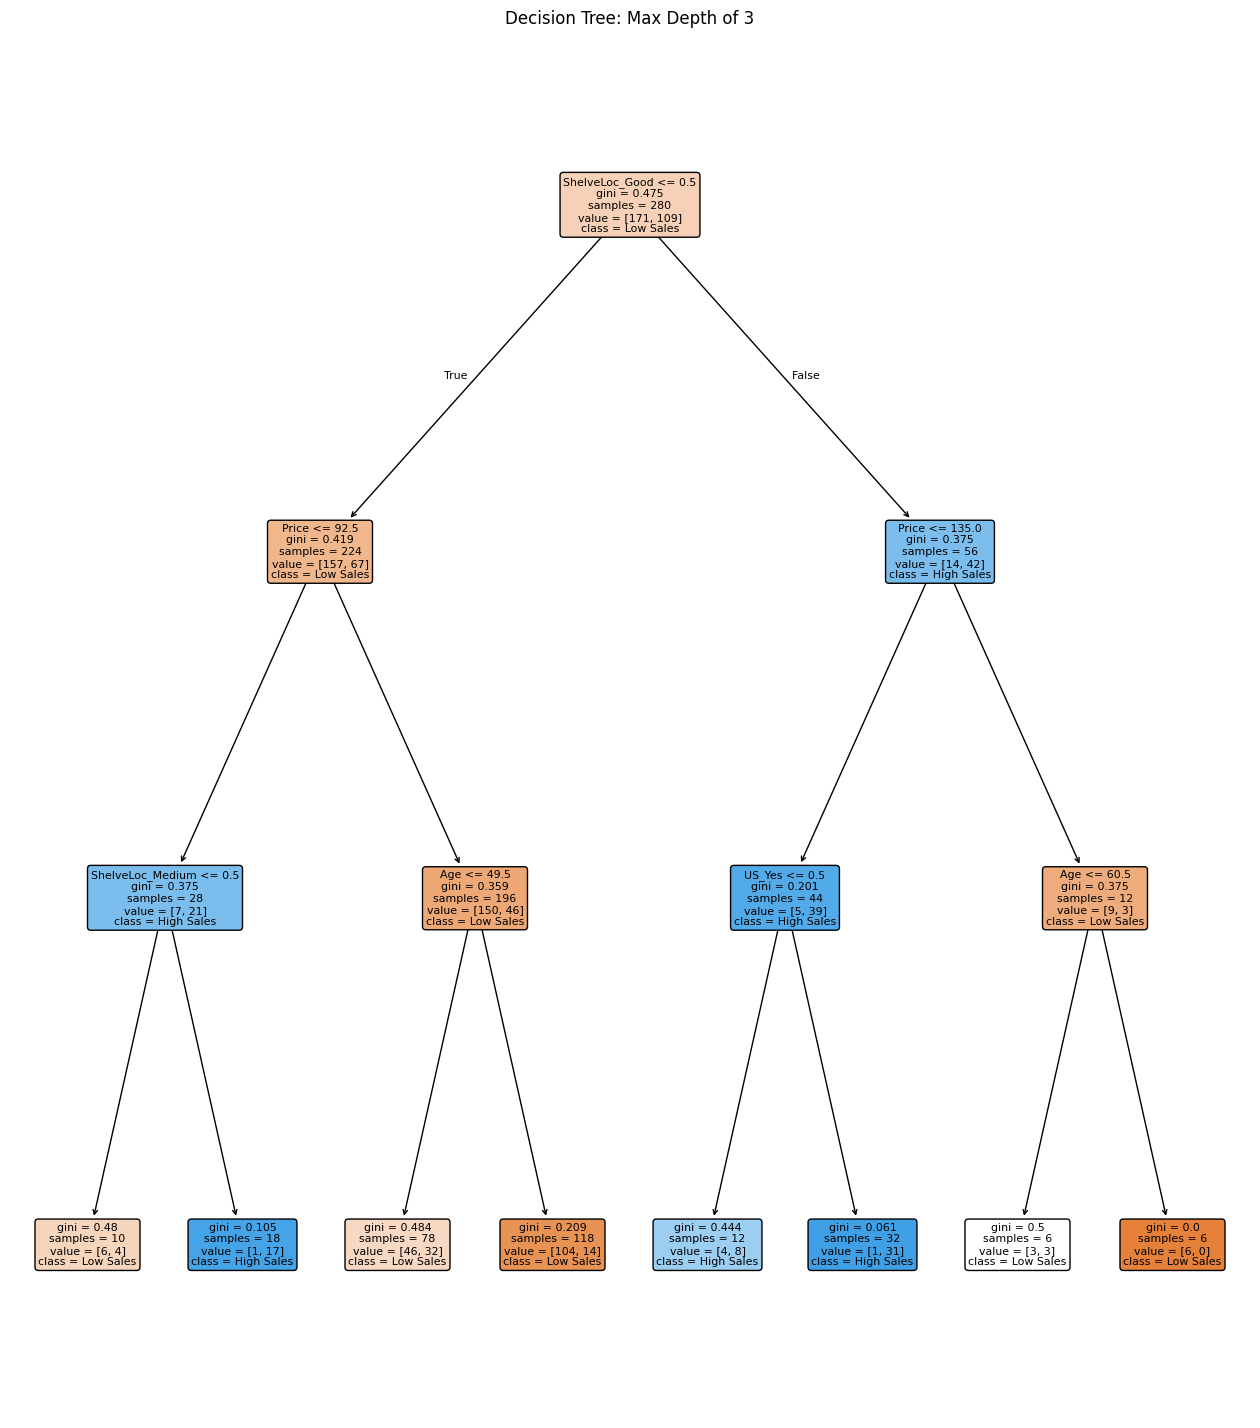

In [7]:
plt.figure(figsize = (16, 18))

plot_tree(tree,
          feature_names = x.columns,
          class_names=['Low Sales', 'High Sales'],
          filled = True,
          rounded = True)

plt.title('Decision Tree: Max Depth of 3')
plt.show()

In [8]:
train_predictions = tree.predict(x_train)
test_predictions = tree.predict(x_test)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("Training Accuracy: ", round(train_accuracy, 4))
print("Testing Accuracy: ", round(test_accuracy, 4))


Training Accuracy:  0.7893
Testing Accuracy:  0.7167


Depths length: 10
Accuracies length: 10


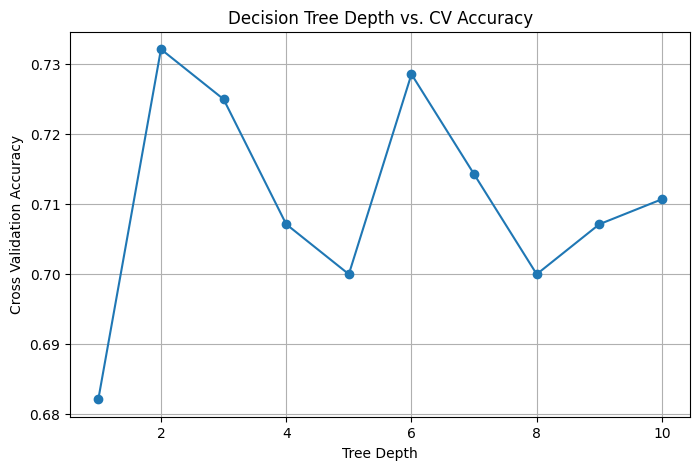

In [9]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
cv_accuracies = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    scores = cross_val_score(clf, x_train, y_train, cv=5)
    cv_accuracies.append(scores.mean())

print("Depths length:", len(depths))
print("Accuracies length:", len(cv_accuracies))

plt.figure(figsize=(8, 5))
plt.oplot if hasattr(plt, 'oplot') else plt.plot(depths, cv_accuracies, marker='o')
plt.xlabel('Tree Depth')
plt.ylabel('Cross Validation Accuracy')
plt.title('Decision Tree Depth vs. CV Accuracy')
plt.grid(True)
plt.show()

In [10]:
best_depth = list(depths)[cv_accuracies.index(max(cv_accuracies))]

print('Best depth:', best_depth)
print('Best CV accuracy:', round(max(cv_accuracies),4))

Best depth: 2
Best CV accuracy: 0.7321


In [11]:
final_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

final_tree.fit(x_train, y_train)

final_predictions = final_tree.predict(x_test)

final_accuracy = accuracy_score(y_test, final_predictions)

print('Final tree depth:', best_depth)
print('Final test accuracy', round(final_accuracy,4))


Final tree depth: 2
Final test accuracy 0.725


In [13]:
root_index = tree.tree_.feature[0]
root_feature = x.columns[root_index]
root_threshold = tree.tree_.threshold[0]

print("Root Predictor:", root_feature)
print("Split Threshold:", round(root_threshold, 2))


Root Predictor: ShelveLoc_Good
Split Threshold: 0.5


# Part 3

1. The first predictor selected by the decision tree was ShelveLoc_Good. The tree splits stores based on this variable because it helps distinguish between high and low sales. Stores on either side of the split have different patterns of sales, which helps the model make predictions.

2. According to the cross validation results, a tree depth of 2 performed best. We use cross validation because it tests the model on multiple portions of the training data, giving us a more reliable estimate of its performance. We should not use test accuracy to choose the depth because the test data should be saved for evaluating the final model.

3. No, increasing tree depth does not always improve cross validation accuracy. Deeper trees can become too complex and start overfitting the training data. In my graph, the highest cross validation accuracy occurred at depth 2. The results show that increasing complexity does not necessarily make a model better at predicting new data. The accuracy fluctuated after the best depth of 2.


# Additional Questions:

1. A leaf predicts a category or class, such as high or low sales. In a regression tree, a leaf predicts a numerical value such as the average target value of the training observations in that leaf.

2. The full tree reached 100% training accuracy because it overfit the training data. It learned very specific patterns, including noise, instead of just general trends. This made it less accurate when predicting new data.

3. Two ways to limit tree complexity are setting a maximum depth and requiring a minimum number of samples in each leaf. Cross validation helped me find the best maximum depth

4. Decision trees don't need feature scaling because they make predictions by splitting data based on feature values and thresholds. Changing the scale of a feature doesn't change the order of its values, so it doesn't affect how the tree makes its decisions

5. An importance of 0 only means that age did not reduce impurity in any of the splits used by that particular tree. It doesn't mean age is unrelated to heart disease. Other features might have been selected instead, or age might be useful in a different model

6. One strength of a decision tree is that it's easy to visualize and understand how it makes predictions. One weakness is that it can overfit the training data especially if the tree becomes too deep.

